# HighDimensions (PyTorch)

Notebook for exploring high-dimensional X with a PyTorch MLP instead of scikit-learn MLPClassifier.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score

# Reproducibility
np.random.seed(41)
torch.manual_seed(41)

# Device setup (GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


In [2]:
# Generate 1000 samples with 28000 features
# Each feature is normally distributed with mean=0 and std=1
X = np.random.normal(loc=0, scale=1, size=(1000, 28000)).astype(np.float32)
X.shape

(1000, 28000)

In [3]:
# Split first 10 features into two groups and apply shifts
X[0:500, :10] += -3  # First half shifted by -3
X[500:1000, :10] += 3  # Second half shifted by +3

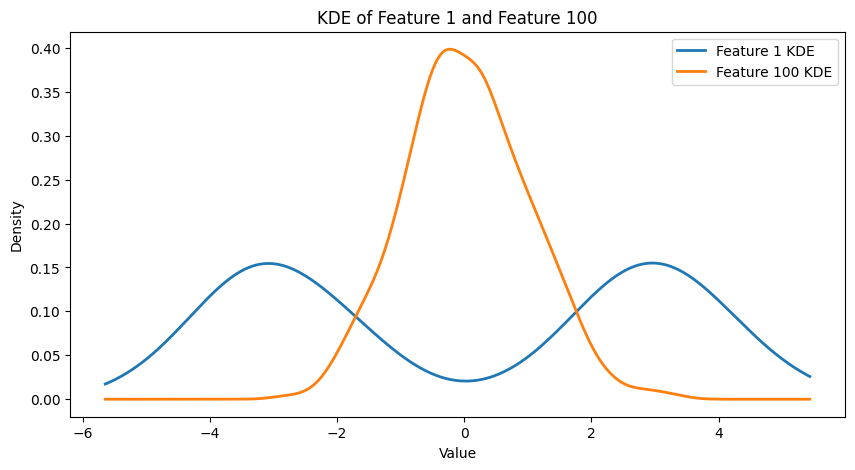

In [4]:
feature_1 = X[:, 0]
feature_100 = X[:, 99]

x_min = min(feature_1.min(), feature_100.min())
x_max = max(feature_1.max(), feature_100.max())
x_grid = np.linspace(x_min, x_max, 400)

kde_feature_1 = gaussian_kde(feature_1)
kde_feature_100 = gaussian_kde(feature_100)

plt.figure(figsize=(10, 5))
plt.plot(x_grid, kde_feature_1(x_grid), label='Feature 1 KDE', linewidth=2)
plt.plot(x_grid, kde_feature_100(x_grid), label='Feature 100 KDE', linewidth=2)
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('KDE of Feature 1 and Feature 100')
plt.legend()
plt.show()

In [5]:
n_samples = X.shape[0]
y = np.zeros(n_samples, dtype=np.int64)
y[n_samples // 2:] = 1

y.shape, np.bincount(y)
y[:10], y[490:510], y[-10:]

(array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
 array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]),
 array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1]))

In [6]:
X_df = pd.DataFrame(X, columns=[f'feature_{i+1}' for i in range(X.shape[1])])
y_df = pd.DataFrame(y, columns=['y'])

X_df.shape, y_df.shape

((1000, 28000), (1000, 1))

Weight init seed: 42
Termination cause: converged by tolerance
Iterations run: 550
Test accuracy: 0.48
Final loss: 0.08152519911527634


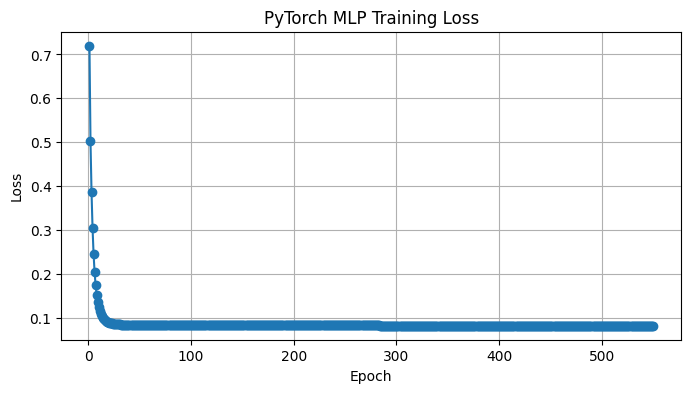

In [19]:
# Use X_df as input and y_df as output
X_data = X_df.values
y_data = y_df['y'].values

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42, stratify=y_data
)

# Standardize (same idea as scikit pipeline)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# Convert to tensors and move to selected device
X_train_t = torch.tensor(X_train, dtype=torch.float32).to(device)
X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1).to(device)
y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1).to(device)

class MLPBinary(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 5),
            nn.ReLU(),
            nn.Linear(5, 1)
        )

    def forward(self, x):
        return self.net(x)

# Weight-initialization seed (change this value as desired)
weight_init_seed = 42
torch.manual_seed(weight_init_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(weight_init_seed)
print(f'Weight init seed: {weight_init_seed}')

model = MLPBinary(input_dim=X_train_t.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Match scikit-style termination: max_iter + tolerance with patience
max_iter = 10000
tol = 1e-5
n_iter_no_change = 10

loss_values = []
best_loss = float('inf')
no_improve_count = 0
termination_cause = 'reached max_iter'

for epoch in range(max_iter):
    model.train()
    optimizer.zero_grad()

    logits = model(X_train_t)
    loss = criterion(logits, y_train_t)
    loss.backward()
    optimizer.step()

    current_loss = loss.item()
    loss_values.append(current_loss)

    if best_loss - current_loss > tol:
        best_loss = current_loss
        no_improve_count = 0
    else:
        no_improve_count += 1

    if no_improve_count >= n_iter_no_change:
        termination_cause = 'converged by tolerance'
        break

print(f'Termination cause: {termination_cause}')
print(f'Iterations run: {len(loss_values)}')

# Evaluate
model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs = torch.sigmoid(test_logits)
    y_pred = (test_probs >= 0.5).int().cpu().numpy().ravel()

print('Test accuracy:', accuracy_score(y_test, y_pred))
print('Final loss:', loss_values[-1])

# Plot loss curve
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(loss_values) + 1), loss_values, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('PyTorch MLP Training Loss')
plt.grid(True)
plt.show()

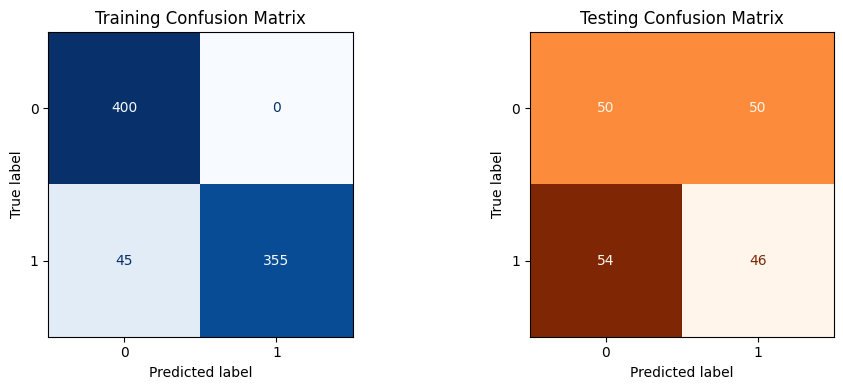

Training CM:
 [[400   0]
 [ 45 355]]
Testing CM:
 [[50 50]
 [54 46]]


In [20]:
# Predictions for train and test
model.eval()
with torch.no_grad():
    train_probs = torch.sigmoid(model(X_train_t))
    test_probs = torch.sigmoid(model(X_test_t))
    y_train_pred = (train_probs >= 0.5).int().cpu().numpy().ravel()
    y_test_pred = (test_probs >= 0.5).int().cpu().numpy().ravel()

# Confusion matrices
cm_train = confusion_matrix(y_train, y_train_pred)
cm_test = confusion_matrix(y_test, y_test_pred)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=[0, 1]).plot(
    ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title('Training Confusion Matrix')

ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=[0, 1]).plot(
    ax=axes[1], cmap='Oranges', colorbar=False
)
axes[1].set_title('Testing Confusion Matrix')

plt.tight_layout()
plt.show()

print('Training CM:\n', cm_train)
print('Testing CM:\n', cm_test)

In [21]:
# Per-class F1 (class 0, class 1)
f1_per_class = f1_score(y_test, y_test_pred, average=None, labels=[0, 1])

# Combined F1 scores
f1_macro = f1_score(y_test, y_test_pred, average='macro')
f1_weighted = f1_score(y_test, y_test_pred, average='weighted')
f1_micro = f1_score(y_test, y_test_pred, average='micro')

print(f'F1 class 0: {f1_per_class[0]:.4f}')
print(f'F1 class 1: {f1_per_class[1]:.4f}')
print(f'F1 combined (macro): {f1_macro:.4f}')
print(f'F1 combined (weighted): {f1_weighted:.4f}')
print(f'F1 combined (micro): {f1_micro:.4f}')

F1 class 0: 0.4902
F1 class 1: 0.4694
F1 combined (macro): 0.4798
F1 combined (weighted): 0.4798
F1 combined (micro): 0.4800
